# Where New Users Drop Out: the Identity Check

A finance app must verify every new user's identity before they can use it (KYC, "know your customer"): an ID document, a selfie, and a proof of address, then a review. Each step loses people. This notebook looks at:

1. how many users finish each step,
2. who gets rejected, where, and why,
3. how many retry after a rejection,
4. what approved users do next: get a card or an IBAN account.

**Data:** synthetic, generated by [make_data.py](make_data.py).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (12, 4.5), "axes.spines.top": False, "axes.spines.right": False})

In [2]:
users = pd.read_csv("users.csv", parse_dates=["signup_date", "approved_at"])
print(f"{len(users):,} sign-ups, {users.signup_date.min():%b %Y} to {users.signup_date.max():%b %Y}")
users.head()

12,000 sign-ups, Jan 2024 to Dec 2025


,user_id,signup_date,country,channel,device,kyc_last_step,kyc_status,kyc_attempts,reject_reason,approved_at,has_card,has_iban
0,100001,2024-01-01,Mexico,organic,iOS,review,rejected,1,selfie doesn't match,NaT,False,False
1,100002,2024-01-01,Spain,organic,iOS,started,abandoned,1,NaN,NaT,False,False
2,100003,2024-01-01,Germany,paid ads,iOS,review,approved,2,NaN,2024-01-01 12:30:05.332168957,False,True
3,100004,2024-01-01,Nigeria,paid ads,iOS,review,rejected,1,selfie doesn't match,NaT,False,False
4,100005,2024-01-02,Argentina,organic,iOS,review,rejected,1,blurry or cut-off document,NaT,False,False


In [3]:
users.kyc_status.value_counts(normalize=True).round(3).rename("share of sign-ups")

kyc_status
approved     0.541
abandoned    0.399
rejected     0.060
Name: share of sign-ups, dtype: float64

## 1. The funnel

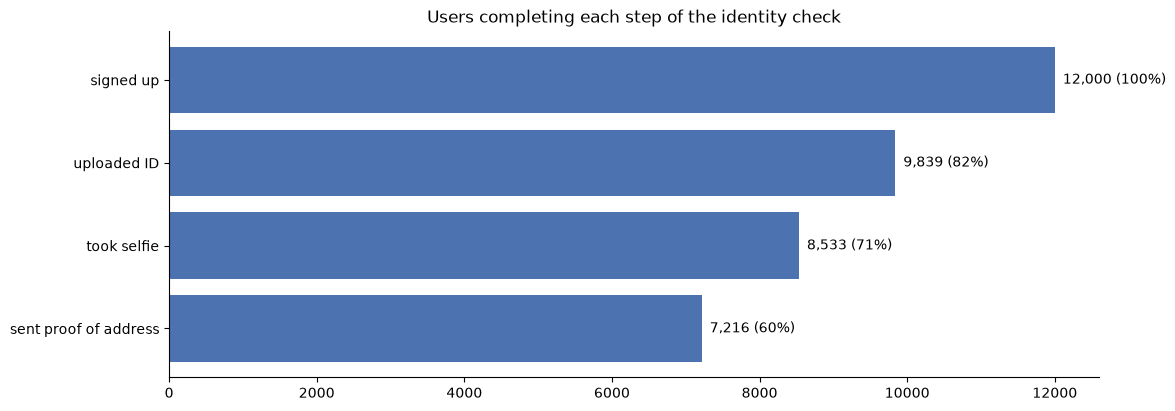

In [4]:
steps = ["started", "id_document", "selfie", "proof_of_address"]
labels = ["signed up", "uploaded ID", "took selfie", "sent proof of address"]
order = {s: i for i, s in enumerate(steps + ["review"])}
reached = users.kyc_last_step.map(order)
funnel = pd.Series([(reached >= i).sum() for i in range(len(steps))], index=labels)

fig, ax = plt.subplots()
ax.barh(funnel.index[::-1], funnel.values[::-1], color="#4c72b0")
for y, (n, share) in enumerate(zip(funnel.values[::-1], (funnel / funnel.iloc[0]).values[::-1])):
    ax.text(n, y, f"  {n:,} ({share:.0%})", va="center")
ax.set_title("Users completing each step of the identity check")
plt.show()

Which step loses the most, and does the device matter? Share of users who uploaded an ID but stopped at the selfie:

In [5]:
uploaded_id = users[reached >= 1]
selfie_drop = uploaded_id.groupby("device").apply(lambda d: (d.kyc_last_step == "id_document").mean())
selfie_drop.round(3).rename("stopped at the selfie")

device
Android    0.118
iOS        0.124
web        0.200
Name: stopped at the selfie, dtype: float64

Taking a selfie with a laptop camera is clumsy: 20% of web users stop at that step, against about 12% on phones. A practical fix is to let web users continue on their phone with a QR code.

## 2. Rejections by country and reason

Rejection rate among users who finished all steps:

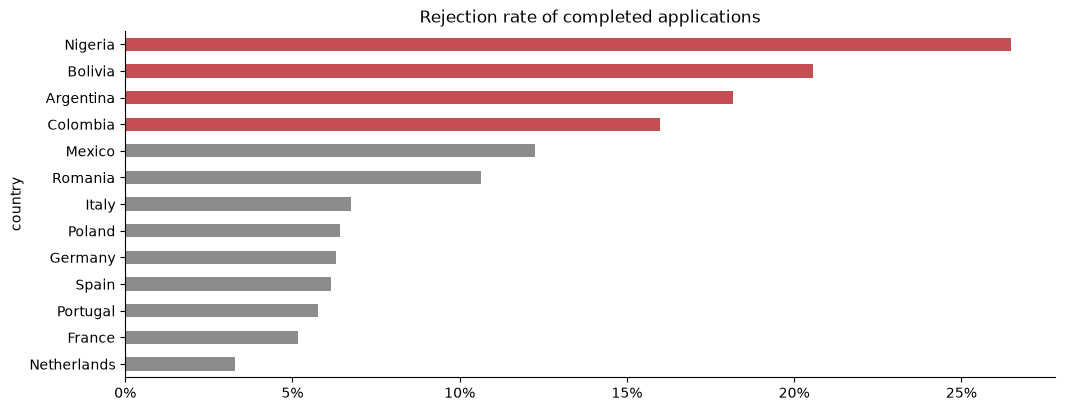

In [6]:
finished = users[users.kyc_status != "abandoned"]
reject_rate = finished.groupby("country").kyc_status.apply(lambda s: (s == "rejected").mean()).sort_values()

fig, ax = plt.subplots()
reject_rate.plot.barh(ax=ax, color=np.where(reject_rate > 0.15, "#c44e52", "#8c8c8c"))
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_title("Rejection rate of completed applications")
plt.show()

In [7]:
latam = ["Argentina", "Bolivia", "Colombia", "Mexico"]
rejected = users[users.kyc_status == "rejected"].copy()
rejected["region"] = np.where(rejected.country.isin(latam), "Latin America", "Europe and other")
pd.crosstab(rejected.reject_reason, rejected.region, normalize="columns").round(2).sort_values("Latin America", ascending=False)

region,Europe and other,Latin America
reject_reason,,
blurry or cut-off document,0.33,0.55
selfie doesn't match,0.19,0.16
document expired,0.13,0.11
proof of address too old,0.16,0.11
unsupported country,0.09,0.04
suspected fraud,0.10,0.03


In Latin America more than half of rejections are blurry or cut-off document photos, a problem the app can solve before the review: check the photo's sharpness and framing on the phone and ask for a retake right away.

## 3. Retries

In [8]:
attempts = pd.crosstab(users.kyc_attempts, users.kyc_status)
attempts

kyc_status,abandoned,approved,rejected
kyc_attempts,,,
1,2410,5613,640
2,2374,794,70
3,0,84,6
4,0,6,3


In [9]:
approved = users[users.kyc_status == "approved"]
hours = (approved.approved_at - approved.signup_date).dt.total_seconds() / 3600
print(f"median time from sign-up to approval: {hours.median():.0f} hours")
print(f"approved users who needed more than one attempt: {(approved.kyc_attempts > 1).mean():.1%}")

median time from sign-up to approval: 16 hours
approved users who needed more than one attempt: 13.6%


## 4. After approval: cards and IBAN accounts

The payment card is only offered in the EU, so its uptake is measured among approved users in the EU. The IBAN account is offered everywhere.

In [10]:
eu = ["Spain", "Germany", "France", "Italy", "Portugal", "Poland", "Netherlands", "Romania"]
approved = approved.assign(region=np.where(approved.country.isin(eu), "EU", "outside EU"))
uptake = approved.groupby("region")[["has_card", "has_iban"]].mean()
uptake.loc["outside EU", "has_card"] = np.nan    # not offered there
uptake.round(3)

,has_card,has_iban
region,,
EU,0.326,0.419
outside EU,NaN,0.219


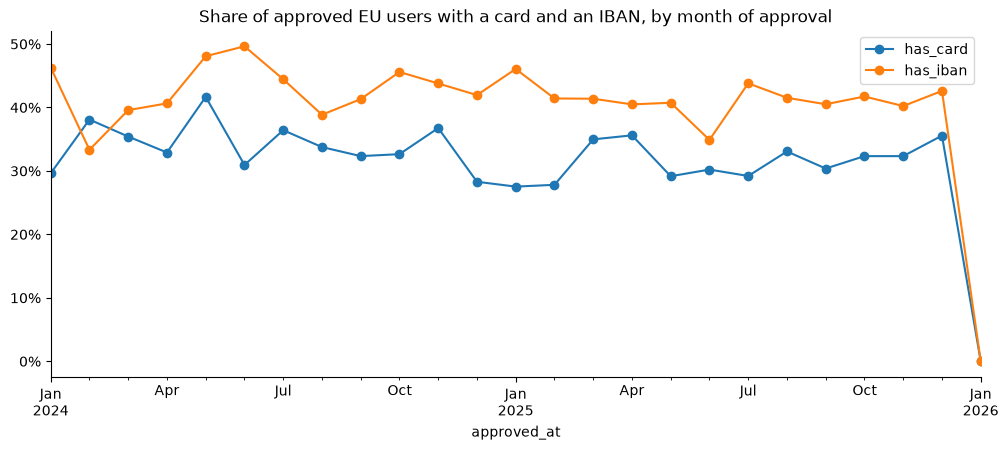

In [11]:
monthly = approved[approved.region == "EU"].groupby(approved.approved_at.dt.to_period("M"))[["has_card", "has_iban"]].mean()
ax = monthly.plot(marker="o", title="Share of approved EU users with a card and an IBAN, by month of approval")
ax.yaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
plt.show()

## Results

- About 4 in 10 sign-ups never finish the identity check. The biggest loss is the first step, uploading an ID.
- 20% of web users stop at the selfie, against about 12% of phone users.
- Rejection rates range from about 3% in the Netherlands to over 20% in Bolivia and Nigeria. In Latin America most rejections are blurry document photos, which an on-phone photo check could prevent.
- Most approved users get through on the first attempt, typically within a day.
- About a third of approved EU users take the card and about 4 in 10 open an IBAN account; outside the EU, about 2 in 10 open an IBAN account.

## Tools

Python, pandas, NumPy, matplotlib